# All Classification Algorithms along with Grid Search and Randomized Search

# Classification Algorithm

### Iris Dataset

### Objective: Predict Flower Species

In [35]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [36]:
data = pd.read_csv("Iris.csv")
data

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...,...
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica


In [37]:
data.columns

Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='object')

In [38]:
data = data[['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species']]

In [39]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SepalLengthCm  150 non-null    float64
 1   SepalWidthCm   150 non-null    float64
 2   PetalLengthCm  150 non-null    float64
 3   PetalWidthCm   150 non-null    float64
 4   Species        150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [40]:
data.isnull().sum()

SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

In [41]:
data.describe()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [42]:
data["Species"].value_counts()

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

In [43]:
species_mapping = {"Iris-setosa":0,"Iris-versicolor":1,"Iris-virginica":2}
data["Species_encoded"] = data["Species"].map(species_mapping)

In [44]:
data

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,Species_encoded
0,5.1,3.5,1.4,0.2,Iris-setosa,0
1,4.9,3.0,1.4,0.2,Iris-setosa,0
2,4.7,3.2,1.3,0.2,Iris-setosa,0
3,4.6,3.1,1.5,0.2,Iris-setosa,0
4,5.0,3.6,1.4,0.2,Iris-setosa,0
...,...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica,2
146,6.3,2.5,5.0,1.9,Iris-virginica,2
147,6.5,3.0,5.2,2.0,Iris-virginica,2
148,6.2,3.4,5.4,2.3,Iris-virginica,2


In [45]:
X = data[['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']]
y = data["Species"]

In [46]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.30)

## Creating First Model: Logistic Regression

In [47]:
from sklearn.linear_model import LogisticRegression
logreg = LogisticRegression()
logreg.fit(X_train,y_train)
y_pred = logreg.predict(X_test)

In [48]:
from sklearn.metrics import accuracy_score
print(accuracy_score(y_test,y_pred))

0.9333333333333333


In [49]:
y_proba = logreg.predict_proba(X_test)
y_proba

array([[2.15836919e-02, 9.08863707e-01, 6.95526007e-02],
       [1.84851758e-04, 1.44891695e-01, 8.54923453e-01],
       [3.69030153e-02, 9.41445346e-01, 2.16516388e-02],
       [9.65300400e-01, 3.46995038e-02, 9.62389575e-08],
       [1.60130573e-05, 3.14657813e-02, 9.68518206e-01],
       [1.16614220e-05, 5.21915363e-02, 9.47796802e-01],
       [9.69443519e-01, 3.05564039e-02, 7.73450758e-08],
       [1.39810126e-03, 2.91507013e-01, 7.07094886e-01],
       [4.61762183e-04, 2.79714707e-01, 7.19823531e-01],
       [9.74650937e-01, 2.53489584e-02, 1.04532772e-07],
       [8.10065117e-03, 8.27214460e-01, 1.64684889e-01],
       [2.67398304e-05, 4.86619922e-02, 9.51311268e-01],
       [2.86177174e-01, 7.12390012e-01, 1.43281435e-03],
       [4.31858422e-05, 7.51102664e-02, 9.24846548e-01],
       [1.08042648e-02, 8.47050194e-01, 1.42145541e-01],
       [1.29133156e-04, 1.32268844e-01, 8.67602023e-01],
       [9.85782797e-01, 1.42171740e-02, 2.93277137e-08],
       [1.11709347e-04, 6.80910

In [50]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        15
Iris-versicolor       0.92      0.86      0.89        14
 Iris-virginica       0.88      0.94      0.91        16

       accuracy                           0.93        45
      macro avg       0.94      0.93      0.93        45
   weighted avg       0.93      0.93      0.93        45



In [51]:
from sklearn.metrics import confusion_matrix

In [52]:
cm = confusion_matrix(y_test,y_pred)
cm

array([[15,  0,  0],
       [ 0, 12,  2],
       [ 0,  1, 15]])

In [53]:
from sklearn.metrics import ConfusionMatrixDisplay

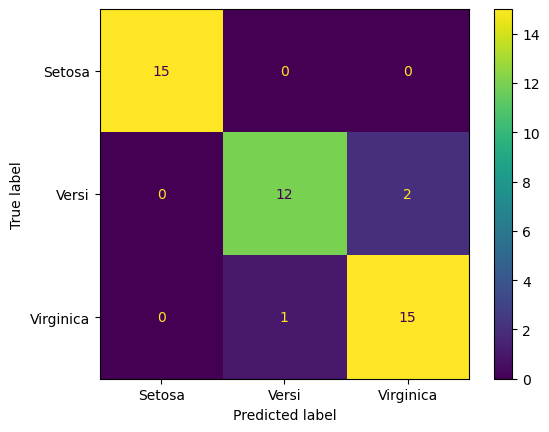

In [54]:
disp = ConfusionMatrixDisplay(cm,display_labels=["Setosa","Versi","Virginica"])
disp.plot()
plt.show()

In [55]:
from sklearn.metrics import roc_auc_score
roc_auc = roc_auc_score(y_test,y_proba,multi_class="ovr")
roc_auc

np.float64(0.9940542401610255)

# Experiment with Next Model : Decision Trees

In [56]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier()
dt.fit(X_train,y_train)
y_pred_dt = dt.predict(X_test)

In [57]:
print(classification_report(y_test,y_pred_dt))

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        15
Iris-versicolor       0.92      0.86      0.89        14
 Iris-virginica       0.88      0.94      0.91        16

       accuracy                           0.93        45
      macro avg       0.94      0.93      0.93        45
   weighted avg       0.93      0.93      0.93        45



# Experiment : Decision Trees with Hyperparameter Tuning

In [58]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(max_depth=2,min_samples_split=15)
dt.fit(X_train,y_train)
y_pred_dt = dt.predict(X_test)
print(classification_report(y_test,y_pred_dt))

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        15
Iris-versicolor       0.92      0.79      0.85        14
 Iris-virginica       0.83      0.94      0.88        16

       accuracy                           0.91        45
      macro avg       0.92      0.91      0.91        45
   weighted avg       0.91      0.91      0.91        45



# Experiment : Ensemble Modelling with Random Forest

In [59]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier()
rf.fit(X_train,y_train)
y_pred_rf = rf.predict(X_test)
print(classification_report(y_test,y_pred_rf))

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        15
Iris-versicolor       0.92      0.86      0.89        14
 Iris-virginica       0.88      0.94      0.91        16

       accuracy                           0.93        45
      macro avg       0.94      0.93      0.93        45
   weighted avg       0.93      0.93      0.93        45



# Experiment : Random Forest with Hyper parameter Tuning

In [60]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=200)
rf.fit(X_train,y_train)
y_pred_rf = rf.predict(X_test)
print(classification_report(y_test,y_pred_rf))

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        15
Iris-versicolor       0.92      0.86      0.89        14
 Iris-virginica       0.88      0.94      0.91        16

       accuracy                           0.93        45
      macro avg       0.94      0.93      0.93        45
   weighted avg       0.93      0.93      0.93        45



# Experiment : Naive Bayes Model

Important: MultinomialNB requires non-negative feature values. The original Iris features are non-negative, so it works directly.
If you standardize with StandardScaler, you'll get negative values and MultinomialNB will fail.

In [61]:
from sklearn.naive_bayes import MultinomialNB

# Create Multinomial Naive Bayes Model
mnb = MultinomialNB()

# Train Model
mnb.fit(X_train, y_train)

# Predictions
y_pred = mnb.predict(X_test)

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        15
Iris-versicolor       0.82      1.00      0.90        14
 Iris-virginica       1.00      0.81      0.90        16

       accuracy                           0.93        45
      macro avg       0.94      0.94      0.93        45
   weighted avg       0.95      0.93      0.93        45



# Experiment : Naive Bayes Model - GaussianNB

GaussianNB is actually the preferred Naive Bayes variant for the Iris dataset.

Why GaussianNB?

The Iris features are continuous numerical measurements:Sepal Length,Sepal Width,Petal Length,Petal Width
GaussianNB assumes each feature follows a Gaussian (Normal) distribution within each class, which is a reasonable assumption for Iris.

Why not MultinomialNB? MultinomialNB is designed for:

Word counts
Frequency data
Count-based features
Non-negative integer-like values

Typical use cases:

1. Spam detection
2. Sentiment analysis
3. Document classification

Although Iris contains non-negative values, they are continuous measurements, not counts. Therefore GaussianNB is more appropriate.

In [62]:
# Import libraries
from sklearn.naive_bayes import GaussianNB

# Create model
gnb = GaussianNB()

# Train
gnb.fit(X_train, y_train)

# Predict
y_pred = gnb.predict(X_test)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        15
Iris-versicolor       0.93      0.93      0.93        14
 Iris-virginica       0.94      0.94      0.94        16

       accuracy                           0.96        45
      macro avg       0.96      0.96      0.96        45
   weighted avg       0.96      0.96      0.96        45



# Support Vector Machines (SVM)

In [65]:
from sklearn import svm
svm1 = svm.SVC()
svm1.fit(X_train,y_train)
y_pred_svm =  svm1.predict(X_test)

print(classification_report(y_test, y_pred_svm))

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        15
Iris-versicolor       0.86      0.86      0.86        14
 Iris-virginica       0.88      0.88      0.88        16

       accuracy                           0.91        45
      macro avg       0.91      0.91      0.91        45
   weighted avg       0.91      0.91      0.91        45



# SVM with Kernel change

In [66]:
from sklearn import svm
svm1 = svm.SVC(kernel="poly")
svm1.fit(X_train,y_train)
y_pred_svm =  svm1.predict(X_test)

print(classification_report(y_test, y_pred_svm))

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        15
Iris-versicolor       0.92      0.86      0.89        14
 Iris-virginica       0.88      0.94      0.91        16

       accuracy                           0.93        45
      macro avg       0.94      0.93      0.93        45
   weighted avg       0.93      0.93      0.93        45



# Hyperparameter Tuning

## 1. GridSearchCV

In [67]:
from sklearn.model_selection import GridSearchCV

In [68]:
param_list = {"n_estimators":[100,150,200],"max_depth":[5,8]}

In [70]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier()

In [71]:
grid_search = GridSearchCV(estimator=rf,param_grid=param_list,scoring="accuracy")

In [72]:
grid_search.fit(X_train,y_train)

GridSearchCV(estimator=RandomForestClassifier(),
             param_grid={'max_depth': [5, 8], 'n_estimators': [100, 150, 200]},
             scoring='accuracy')

In [73]:
print(grid_search.best_params_)

{'max_depth': 8, 'n_estimators': 200}


In [74]:
print(grid_search.best_score_)

0.9714285714285715


In [75]:
print(grid_search.best_estimator_)

RandomForestClassifier(max_depth=8, n_estimators=200)


In [76]:
y_pred_grid = grid_search.predict(X_test)

In [77]:
y_pred_grid

array(['Iris-versicolor', 'Iris-virginica', 'Iris-versicolor',
       'Iris-setosa', 'Iris-virginica', 'Iris-virginica', 'Iris-setosa',
       'Iris-virginica', 'Iris-virginica', 'Iris-setosa',
       'Iris-versicolor', 'Iris-virginica', 'Iris-versicolor',
       'Iris-virginica', 'Iris-versicolor', 'Iris-virginica',
       'Iris-setosa', 'Iris-virginica', 'Iris-setosa', 'Iris-virginica',
       'Iris-setosa', 'Iris-versicolor', 'Iris-versicolor',
       'Iris-virginica', 'Iris-setosa', 'Iris-setosa', 'Iris-virginica',
       'Iris-versicolor', 'Iris-setosa', 'Iris-versicolor',
       'Iris-versicolor', 'Iris-setosa', 'Iris-setosa', 'Iris-virginica',
       'Iris-setosa', 'Iris-setosa', 'Iris-virginica', 'Iris-virginica',
       'Iris-setosa', 'Iris-versicolor', 'Iris-versicolor',
       'Iris-virginica', 'Iris-virginica', 'Iris-versicolor',
       'Iris-setosa'], dtype=object)

## 2. Randomized Search CV

In [78]:
from sklearn.model_selection import RandomizedSearchCV

In [79]:
param_list2 = {"n_estimators":[100,150,200,400,500,600],"max_depth":[5,8,10,15]}

In [82]:
random_search = RandomizedSearchCV(estimator=rf,param_distributions=param_list2,scoring="accuracy")

In [83]:
random_search.fit(X_train,y_train)

RandomizedSearchCV(estimator=RandomForestClassifier(),
                   param_distributions={'max_depth': [5, 8, 10, 15],
                                        'n_estimators': [100, 150, 200, 400,
                                                         500, 600]},
                   scoring='accuracy')

In [84]:
y_pred_randomized = random_search.predict(X_test)

In [85]:
print(random_search.best_estimator_)

RandomForestClassifier(max_depth=8, n_estimators=500)
